# 03 - Gated multimodal fusion on SDXL (conflict detector + gating MLP + constraint guidance)

Standalone notebook (reloads everything, so you do not need notebook 02's runtime). Frozen: SDXL, scribble ControlNet, IP-Adapter, CLIP, DINOv2.
Trained: only the small gating MLP.

**Pipeline**
1. Build items: normal rows plus labeled conflicts from `metadata_with_conflicts.jsonl` (run notebook 01b first): `sem` caption vs sketch object, `color` and `material` caption vs reference, `app` swapped reference.
2. Conflict detector: cached CLIP similarities between modalities per attribute (object, appearance) -> 6 features.
3. Stage A: generate a small grid of (ControlNet scale, IP-Adapter scale) per train item, score each image, build soft-best targets.
4. Train the gating MLP (features -> ControlNet amplitude, IP-Adapter amplitude). Per-step weights = amplitude x a fixed schedule (geometry first, appearance later).
5. Stage B on the test split: `fixed`, `scheduled`, `gate`, `gate_guided` (latent guidance with sketch-edge geometry loss and attribute-level appearance loss during denoising).
6. Results table by item kind, contact sheet, and a manifest for `eval_metrics.py`.

Metrics here are a compact set (CLIP-T, CLIP-I, DINO-I, sketch-edge recall, attribute-appearance similarity). Run your full `eval_metrics.py` on the saved manifest afterwards for the report.

Memory: SDXL parts + CLIP + DINO ~ 12 GB on GPU while encoding, ~9.5 GB after the SDXL text/image encoders are freed. Guidance adds a small low-resolution VAE decode with gradients. Peak is printed after the sanity cell.
Expected runtime with defaults (RES 640, 20 steps, ~220 grid images + ~140 eval images): roughly 1.5 to 2 hours on a T4. Everything is resumable.

In [1]:
# ---- CONFIG ----
DRIVE_ROOT = "/content/drive/MyDrive/sketchy_dataset_one_sketch"
ZIP_PATH = f"{DRIVE_ROOT}/pilot_v1.zip"
LOCAL_DATA = "/content/pilot_v1"
RUN = "gated_v1"
OUT = f"{DRIVE_ROOT}/sdxl_runs/{RUN}"

RES, STEPS, CFG = 640, 20, 7.0
NEG = "blurry, low quality, text, watermark, multiple objects, cropped"

# items. Conflict rows come from notebook 01b's metadata_with_conflicts.jsonl (falls back to in-notebook synthetic swaps if it is missing)
CONFLICT_FILE = f"{DRIVE_ROOT}/metadata_with_conflicts.jsonl"
KIND_OF = {"object_text_sketch": "sem", "color_text_ref": "color", "material_text_ref": "material", "appearance_ref_swap": "app"}
N_TRAIN = dict(normal=20, sem=6, color=4, material=3, app=6)    # train split: used for the grid + gate training
N_EVAL = dict(normal=20, sem=6, color=4, material=3, app=6)     # test split

# Stage A grid
CS_GRID = [0.5, 1.0]
IP_GRID = [0.2, 0.5, 0.8]
CS_RANGE, IP_RANGE = (0.3, 1.2), (0.1, 1.0)   # gate output ranges
FIXED = (1.0, 0.6)                            # baseline amplitudes
SOFT_TEMP = 0.5                               # softmax temperature for grid targets

# constraint guidance
GUIDE_W, GUIDE_START, GUIDE_END, GUIDE_EVERY = 0.25, 0.25, 0.75, 2
LAMBDA_GEO, LAMBDA_APP = 1.0, 1.0

BASE_ID = "stabilityai/stable-diffusion-xl-base-1.0"
VAE_ID = "madebyollin/sdxl-vae-fp16-fix"
CN_ID = "xinsir/controlnet-scribble-sdxl-1.0"
IP_REPO, IP_SUBFOLDER, IP_WEIGHT, ENC_SUBFOLDER = "h94/IP-Adapter", "sdxl_models", "ip-adapter_sdxl_vit-h.safetensors", "models/image_encoder"
CLIP_ID, DINO_ID = "openai/clip-vit-large-patch14", "facebook/dinov2-small"

In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


In [3]:
!pip install -q -U diffusers transformers accelerate safetensors
import torch, json, glob, zipfile, hashlib, time, gc, psutil, random
import numpy as np, pandas as pd
import torch.nn.functional as F
from PIL import Image, ImageOps, ImageFilter
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
print("GPU:", torch.cuda.get_device_name(0), "|", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

GPU: Tesla T4 | 15.6 GB


In [6]:
if not glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True):
    os.makedirs(LOCAL_DATA, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_DATA)
meta_path = glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True)[0]
DATA_DIR = os.path.dirname(meta_path)
raw = [json.loads(l) for l in open(meta_path) if l.strip()]
SPLITS = {s: [r for r in raw if r["split"] == s] for s in ("train", "val", "test")}
print({k: len(v) for k, v in SPLITS.items()})

def resolve(p):
    full = os.path.join(DATA_DIR, p)
    assert os.path.exists(full), full
    return full

def letterbox(im, size, fill):
    im = ImageOps.contain(im, (size, size), Image.LANCZOS)
    c = Image.new("RGB", (size, size), fill)
    c.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return c

def prep_sketch(path):     # white lines on black for the ControlNet
    im = Image.open(path).convert("L")
    if np.array(im).mean() > 127:
        im = ImageOps.invert(im)
    return letterbox(im.convert("RGB"), RES, (0, 0, 0))

def prep_ref(path):
    return letterbox(Image.open(path).convert("RGB"), RES, (127, 127, 127))

def attr_phrase(r):
    return f"a {r['ref_finish']} {r['ref_material']} object in {r['ref_colors']} colors"

def seed_for(s):
    return int(hashlib.md5(str(s).encode()).hexdigest()[:8], 16)

def make_items(pool, n):
    items = []
    def item(base, kind, cap_from=None, ref_from=None):
        c, rf = cap_from or base, ref_from or base
        return dict(key=f"{base['id']}_{kind}", kind=kind, base=base["id"], base_row=base,
                    caption=c["caption"], cap_category=c["category"],
                    ref=rf["reference"], attr=attr_phrase(rf), seed=seed_for(base["id"]))
    for r in pool[:n["normal"]]:
        items.append(item(r, "normal"))
    for k in range(n["sem"]):
        base = pool[k]
        partner = next(p for p in pool[k + 1:] + pool[:k] if p["category"] != base["category"])
        items.append(item(base, "sem", cap_from=partner))
    for k in range(n["app"]):
        base = pool[(n["sem"] + k) % len(pool)]
        partner = next(p for p in pool if p["ref_colors"] != base["ref_colors"] and p["id"] != base["id"])
        items.append(item(base, "app", ref_from=partner))
    return items

def row_item(r, kind):
    bid = r.get("original_id", r["id"])
    return dict(key=r["id"], kind=kind, base=bid, base_row=r, caption=r["caption"],
                cap_category=r.get("caption_category", r["category"]), ref=r["reference"],
                attr=attr_phrase(r), seed=seed_for(bid))

def make_items_from_file(rows_all, split, n):
    pool = [r for r in rows_all if r["split"] == split]
    items = []
    for kind, k in n.items():
        sel = [r for r in pool if (r["conflict_type"] == "none" if kind == "normal" else KIND_OF.get(r["conflict_type"]) == kind)][:k]
        items += [row_item(r, kind) for r in sel]
    return items

if os.path.exists(CONFLICT_FILE):
    rows_all = [json.loads(l) for l in open(CONFLICT_FILE) if l.strip()]
    train_items = make_items_from_file(rows_all, "train", N_TRAIN)
    eval_items = make_items_from_file(rows_all, "test", N_EVAL)
    print("using conflict rows from", CONFLICT_FILE)
else:
    syn = lambda n: {k: v for k, v in n.items() if k in ("normal", "sem", "app")}
    train_items = make_items(SPLITS["train"], syn(N_TRAIN))
    eval_items = make_items(SPLITS["test"], syn(N_EVAL))
    print("WARNING: conflict file not found; using in-notebook synthetic conflicts (run notebook 01b first for the labeled set)")
KINDS = [k for k in ("normal", "sem", "color", "material", "app") if any(i["kind"] == k for i in eval_items)]
print("eval kinds:", {k: sum(i["kind"] == k for i in eval_items) for k in KINDS})
ALL_ITEMS = train_items + eval_items
print(f"train items: {len(train_items)} | eval items: {len(eval_items)}")
for it in [next(i for i in train_items if i["kind"] == k) for k in KINDS]:
    print(it["kind"], "|", it["caption"], "| cap_cat:", it["cap_category"], "| base cat:", it["base_row"]["category"], "| ref attr:", it["attr"])

{'train': 160, 'val': 20, 'test': 20}
using conflict rows from /content/drive/MyDrive/sketchy_dataset_one_sketch/metadata_with_conflicts.jsonl
eval kinds: {'normal': 20, 'sem': 6, 'color': 4, 'material': 3, 'app': 6}
train items: 39 | eval items: 39
normal | Blue-handled hammer with wooden handle. | cap_cat: hammer | base cat: hammer | ref attr: a glossy plastic object in blue and white colors
sem | A person holds a shiny, silver French horn. | cap_cat: trumpet | base cat: hammer | ref attr: a glossy plastic object in blue and white colors
color | Pink-handled hammer with wooden handle. | cap_cat: hammer | base cat: hammer | ref attr: a glossy plastic object in blue and white colors
material | Blue-handled hammer with stone handle. | cap_cat: hammer | base cat: hammer | ref attr: a glossy plastic object in blue and white colors
app | Blue-handled hammer with wooden handle. | cap_cat: hammer | base cat: hammer | ref attr: a matte solid object in grey colors


In [5]:
dt = torch.float16
from diffusers import (UNet2DConditionModel, ControlNetModel, AutoencoderKL,
                       StableDiffusionXLControlNetPipeline, EulerDiscreteScheduler)
from transformers import (CLIPTextModel, CLIPTextModelWithProjection, CLIPTokenizer,
                          CLIPVisionModelWithProjection, AutoModel)
def ram(): return round(psutil.virtual_memory().used / 1e9, 1)
def gpu(): return round(torch.cuda.memory_allocated() / 1e9, 2)
def to_gpu(m, name):
    m = m.to("cuda"); gc.collect()
    print(f"{name:10s} | RAM {ram()} GB | GPU {gpu()} GB")
    return m

vae = to_gpu(AutoencoderKL.from_pretrained(VAE_ID, torch_dtype=dt), "vae")
unet = to_gpu(UNet2DConditionModel.from_pretrained(BASE_ID, subfolder="unet", torch_dtype=dt, variant="fp16"), "unet")
controlnet = to_gpu(ControlNetModel.from_pretrained(CN_ID, torch_dtype=dt), "controlnet")
te1 = to_gpu(CLIPTextModel.from_pretrained(BASE_ID, subfolder="text_encoder", torch_dtype=dt, variant="fp16"), "text enc 1")
te2 = to_gpu(CLIPTextModelWithProjection.from_pretrained(BASE_ID, subfolder="text_encoder_2", torch_dtype=dt, variant="fp16"), "text enc 2")
enc = to_gpu(CLIPVisionModelWithProjection.from_pretrained(IP_REPO, subfolder=ENC_SUBFOLDER, torch_dtype=dt), "ip enc")
tok1 = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer")
tok2 = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer_2")
sched = EulerDiscreteScheduler.from_pretrained(BASE_ID, subfolder="scheduler")
pipe = StableDiffusionXLControlNetPipeline(vae=vae, text_encoder=te1, text_encoder_2=te2, tokenizer=tok1, tokenizer_2=tok2,
                                           unet=unet, controlnet=controlnet, scheduler=sched, image_encoder=enc)
pipe.load_ip_adapter(IP_REPO, subfolder=IP_SUBFOLDER, weight_name=IP_WEIGHT)
pipe.set_progress_bar_config(disable=True)

CLIPV = to_gpu(CLIPVisionModelWithProjection.from_pretrained(CLIP_ID, torch_dtype=dt), "clip vis")
CLIPT = to_gpu(CLIPTextModelWithProjection.from_pretrained(CLIP_ID, torch_dtype=dt), "clip txt")
CLIPTOK = CLIPTokenizer.from_pretrained(CLIP_ID)
DINO = to_gpu(AutoModel.from_pretrained(DINO_ID, torch_dtype=dt), "dino")
for m in (vae, unet, controlnet, CLIPV, CLIPT, DINO):
    m.requires_grad_(False); m.eval()
print("all models ready | GPU", gpu(), "GB | RAM", ram(), "GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

vae        | RAM 3.0 GB | GPU 0.17 GB


...

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dino       | RAM 4.5 GB | GPU 12.3 GB
all models ready | GPU 12.3 GB | RAM 4.5 GB


In [7]:
# ---- metric / feature helpers (CLIP, DINO, sketch edges) ----
dev = "cuda"
MEAN_C = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=dev).view(1, 3, 1, 1)
STD_C = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=dev).view(1, 3, 1, 1)
MEAN_I = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD_I = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def to_t(pil, size=None):
    if size: pil = pil.resize((size, size), Image.BICUBIC)
    return torch.from_numpy(np.array(pil.convert("RGB"))).permute(2, 0, 1)[None].float().to(dev) / 255

def clip_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(CLIPV(pixel_values=((x - MEAN_C) / STD_C).to(dt)).image_embeds.float(), dim=-1)

@torch.no_grad()
def clip_txt(strs):
    tk = CLIPTOK(strs, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(dev)
    return F.normalize(CLIPT(input_ids=tk.input_ids, attention_mask=tk.attention_mask).text_embeds.float(), dim=-1)

@torch.no_grad()
def dino_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(DINO(pixel_values=((x - MEAN_I) / STD_I).to(dt)).last_hidden_state[:, 0].float(), dim=-1)

def edge_map(x):
    g = x.mean(1, keepdim=True)
    kx = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]], device=x.device).view(1, 1, 3, 3)
    gx, gy = F.conv2d(g, kx, padding=1), F.conv2d(g, kx.transpose(2, 3), padding=1)
    return (gx ** 2 + gy ** 2 + 1e-6).sqrt()

def soft_sketch(sk_pil, size):       # white-on-black sketch -> dilated 0/1 mask at `size`
    t = torch.from_numpy(np.array(sk_pil.convert("L"))).float()[None, None].to(dev) / 255
    t = F.interpolate(t, size=(size, size), mode="area")
    t = (t > 0.35 * t.max()).float()
    return F.max_pool2d(t, 9, 1, 4)

def geo_stats(x, S):                 # recall: edge strength on the sketch; outside: edge strength elsewhere
    E = edge_map(x); E = E / (E.amax() + 1e-6)
    return (E * S).sum() / (S.sum() + 1e-6), (E * (1 - S)).mean()

GL = RES // 16; GH = GL * 8
BASE = {}
with torch.no_grad():
    for it in tqdm(ALL_ITEMS, desc="base caches"):
        bid = it["base"]
        if bid in BASE: continue
        r = it["base_row"]
        sk = prep_sketch(resolve(r["sketch"]))
        sk_orig = letterbox(ImageOps.invert(sk.convert("L")).convert("RGB"), 224, (255, 255, 255))   # dark lines on white for CLIP
        tgt = to_t(Image.open(resolve(r["target"])).convert("RGB"))
        BASE[bid] = dict(sketch=sk, sk_emb=clip_img(to_t(sk_orig)), S_gh=soft_sketch(sk, GH), S_256=soft_sketch(sk, 256),
                         t_clip=clip_img(tgt), t_dino=dino_img(tgt))
print("base caches:", len(BASE))

base caches:   0%|          | 0/78 [00:00<?, ?it/s]

base caches: 40


In [8]:
# ---- encode captions and references once, build conflict-detector features, free SDXL encoders ----
@torch.no_grad()
def encode_text(p):
    return [t.cpu() for t in pipe.encode_prompt(prompt=p, device=dev, num_images_per_prompt=1, do_classifier_free_guidance=True, negative_prompt=NEG)]

@torch.no_grad()
def encode_ip(img):
    return [t.cpu() for t in pipe.prepare_ip_adapter_image_embeds(ip_adapter_image=img, ip_adapter_image_embeds=None, device=dev,
                                                                   num_images_per_prompt=1, do_classifier_free_guidance=True)]
TXT, IPC, REFCLIP = {}, {}, {}
with torch.no_grad():
    for it in tqdm(ALL_ITEMS, desc="encode"):
        if it["caption"] not in TXT: TXT[it["caption"]] = encode_text(it["caption"])
        if it["ref"] not in IPC:
            ref = prep_ref(resolve(it["ref"]))
            IPC[it["ref"]] = encode_ip(ref)
            REFCLIP[it["ref"]] = clip_img(to_t(ref))
        it["cap_emb"] = clip_txt([it["caption"]])
        it["attr_emb"] = clip_txt([it["attr"]])
        cat_emb = clip_txt([f"a photo of a {it['cap_category']}"])
        sk_emb, ref_emb = BASE[it["base"]]["sk_emb"], REFCLIP[it["ref"]]
        cos = lambda a, b: float((a * b).sum())
        it["feat"] = [1 - cos(cat_emb, sk_emb),            # object conflict: text vs sketch
                      1 - cos(cat_emb, ref_emb),           # object conflict: text vs reference
                      1 - cos(it["cap_emb"], it["attr_emb"]),   # appearance conflict: text vs reference attributes
                      1 - cos(sk_emb, ref_emb),            # object conflict: sketch vs reference
                      cos(it["cap_emb"], sk_emb), cos(it["cap_emb"], ref_emb)]
GRAY_IP = encode_ip(Image.new("RGB", (RES, RES), (127, 127, 127)))
pipe.text_encoder = None; pipe.text_encoder_2 = None; pipe.image_encoder = None
del te1, te2, enc
gc.collect(); torch.cuda.empty_cache()
pipe.vae.enable_slicing()
print("encoders freed | GPU", gpu(), "GB | RAM", ram(), "GB")

# conflict detector sanity: do the features separate the item kinds?
train_keys = {t["key"] for t in train_items}
df = pd.DataFrame([dict(kind=i["kind"], split="train" if i["key"] in train_keys else "test",
                        **dict(zip(["obj_text_sketch", "obj_text_ref", "app_text_ref", "obj_sketch_ref", "cos_text_sketch", "cos_text_ref"], i["feat"])))
                   for i in ALL_ITEMS])
print(df.groupby("kind").mean(numeric_only=True).round(3))

encode:   0%|          | 0/78 [00:00<?, ?it/s]

encoders freed | GPU 9.44 GB | RAM 5.1 GB
          obj_text_sketch  obj_text_ref  app_text_ref  obj_sketch_ref  \
kind                                                                    
app                 0.742         0.860         0.597           0.447   
color               0.747         0.838         0.586           0.411   
material            0.760         0.838         0.541           0.426   
normal              0.751         0.840         0.603           0.420   
sem                 0.832         0.865         0.695           0.416   

          cos_text_sketch  cos_text_ref  
kind                                     
app                 0.212         0.073  
color               0.212         0.145  
material            0.194         0.149  
normal              0.207         0.123  
sem                 0.100         0.068  


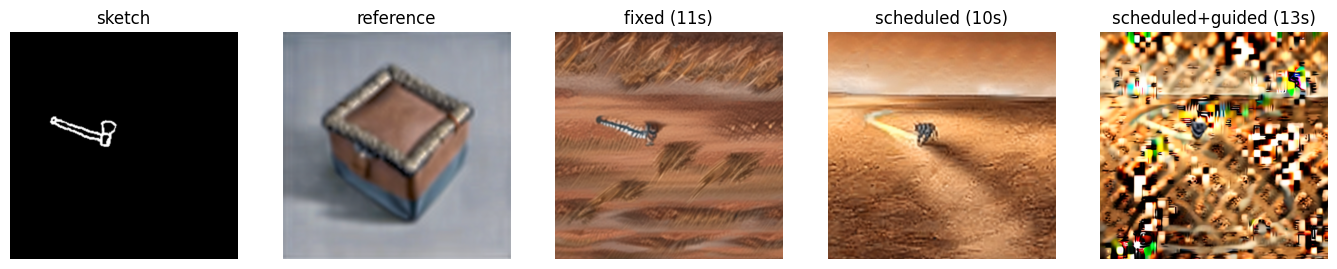

caption: Tiger walks through dry grass. | peak GPU GB: 10.86


In [9]:
# ---- denoising loop with per-step modality weights and optional constraint guidance ----
def cs_shape(f): return 1.0 if f < 0.7 else 0.3                    # geometry first, then relax
def ip_shape(f): return 0.0 if f < 0.15 else min(1.0, (f - 0.15) / 0.25)   # appearance enters later

def guidance_delta(x0, b, it):
    x0g = x0.detach().float().requires_grad_(True)
    with torch.enable_grad():
        z = F.interpolate(x0g, size=(GL, GL), mode="area")
        img = vae.decode((z / vae.config.scaling_factor).to(dt), return_dict=False)[0]
        x = ((img.float() + 1) / 2).clamp(0, 1)
        rec, out = geo_stats(x, b["S_gh"])
        l_geo = (1 - rec) + 0.5 * out                                  # geometry: edges should follow the sketch
        l_app = 1 - (clip_img(x) * it["attr_emb"]).sum()              # appearance: match the reference attributes (not its object)
        g, = torch.autograd.grad(LAMBDA_GEO * l_geo + LAMBDA_APP * l_app, x0g)
    return g / (g.abs().mean() + 1e-8)

@torch.no_grad()
def run_item(it, cs_amp, ip_amp, shaped=True, guided=False):
    b = BASE[it["base"]]
    pe, npe, ppe, nppe = [t.to(dev) for t in TXT[it["caption"]]]
    pr, pooled = torch.cat([npe, pe]), torch.cat([nppe, ppe])
    tid = torch.tensor([[RES, RES, 0, 0, RES, RES]], device=dev, dtype=dt)
    tids = torch.cat([tid, tid])
    ipe = [e.to(dev) for e in IPC[it["ref"]]]
    ctrl = pipe.prepare_image(image=b["sketch"], width=RES, height=RES, batch_size=1, num_images_per_prompt=1,
                              device=dev, dtype=dt, do_classifier_free_guidance=True, guess_mode=False)
    pipe.scheduler.set_timesteps(STEPS, device=dev)
    ts = pipe.scheduler.timesteps
    g = torch.Generator("cpu").manual_seed(it["seed"])
    lat = torch.randn((1, 4, RES // 8, RES // 8), generator=g).to(dev, dt) * pipe.scheduler.init_noise_sigma
    for i, t in enumerate(ts):
        f = i / len(ts)
        cs = cs_amp * (cs_shape(f) if shaped else 1.0)
        ips = ip_amp * (ip_shape(f) if shaped else 1.0)
        li = pipe.scheduler.scale_model_input(torch.cat([lat] * 2), t)
        pipe.set_ip_adapter_scale(float(ips))
        kw = {}
        if cs > 1e-3:
            down, mid = pipe.controlnet(li, t, encoder_hidden_states=pr, controlnet_cond=ctrl, conditioning_scale=float(cs),
                                        guess_mode=False, added_cond_kwargs={"text_embeds": pooled, "time_ids": tids}, return_dict=False)
            kw = dict(down_block_additional_residuals=down, mid_block_additional_residual=mid)
        eps = pipe.unet(li, t, encoder_hidden_states=pr, added_cond_kwargs={"text_embeds": pooled, "time_ids": tids, "image_embeds": ipe},
                        return_dict=False, **kw)[0]
        eu, ec = eps.chunk(2)
        eps = eu + CFG * (ec - eu)
        if guided and GUIDE_START <= f <= GUIDE_END and i % GUIDE_EVERY == 0:
            x0 = lat - pipe.scheduler.sigmas[i].to(dev) * eps          # Euler / epsilon-prediction: x0 = x - sigma * eps
            lat = lat - GUIDE_W * guidance_delta(x0, b, it).to(dt)
        lat = pipe.scheduler.step(eps, t, lat, return_dict=False)[0]
    img = vae.decode(lat / vae.config.scaling_factor, return_dict=False)[0]
    return pipe.image_processor.postprocess(img, output_type="pil")[0]

@torch.no_grad()
def score(img, it):
    b = BASE[it["base"]]
    x = to_t(img); cf = clip_img(x); d = dino_img(x)
    rec, out = geo_stats(to_t(img, 256), b["S_256"])
    return dict(clip_t=float((cf * it["cap_emb"]).sum()), attr=float((cf * it["attr_emb"]).sum()),
                clip_i=float((cf * b["t_clip"]).sum()), dino_i=float((d * b["t_dino"]).sum()),
                recall=float(rec), outside=float(out))

SCORES_PATH = f"{OUT}/scores.json"
SCORES = json.load(open(SCORES_PATH)) if os.path.exists(SCORES_PATH) else {}
def save_scores(): json.dump(SCORES, open(SCORES_PATH, "w"))

def make_or_load(path, key, it, cs, ips, shaped, guided):
    if os.path.exists(path):
        img = Image.open(path).convert("RGB")
    else:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        img = run_item(it, cs, ips, shaped, guided); img.save(path)
    if key not in SCORES:
        SCORES[key] = score(img, it)
    return img

# ---- sanity: one item, plain vs shaped vs guided, with timing and peak memory ----
torch.cuda.reset_peak_memory_stats()
it0 = next(i for i in eval_items if i["kind"] != "normal")       # first conflict item
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
ax[0].imshow(BASE[it0["base"]]["sketch"]); ax[0].set_title("sketch"); ax[1].imshow(prep_ref(resolve(it0["ref"]))); ax[1].set_title("reference")
for a, (nm, kw) in zip(ax[2:], [("fixed", dict(shaped=False, guided=False)), ("scheduled", dict(shaped=True, guided=False)), ("scheduled+guided", dict(shaped=True, guided=True))]):
    t0 = time.time(); im = run_item(it0, *FIXED, **kw); a.imshow(im); a.set_title(f"{nm} ({time.time() - t0:.0f}s)")
for a in ax: a.axis("off")
plt.show()
print("caption:", it0["caption"], "| peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

## Stage A: weight grid on train items, scored
Resumable. Each image is saved to Drive and scored. The best (ControlNet, IP-Adapter) amplitudes per item become the gate's regression targets.

In [10]:
torch.cuda.reset_peak_memory_stats()
for it in tqdm(train_items, desc="grid"):
    for cs in CS_GRID:
        for ip in IP_GRID:
            key = f"grid|{it['key']}|{cs}|{ip}"
            make_or_load(f"{OUT}/grid/cs{cs}_ip{ip}/{it['key']}.png", key, it, cs, ip, True, False)
    save_scores(); torch.cuda.empty_cache()
print("grid done | peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

grid:   0%|          | 0/39 [00:00<?, ?it/s]

grid done | peak GPU GB: 10.5


## Train the gating MLP
Targets: softmax over the per-item grid scores (z-scored CLIP-T + sketch recall + attribute-appearance similarity). Input: the 6 conflict features. The result is compared with a constant predictor on a held-out slice of the train items.

In [11]:
import torch.nn as nn
rows_ = []
for it in train_items:
    for cs in CS_GRID:
        for ip in IP_GRID:
            s = SCORES[f"grid|{it['key']}|{cs}|{ip}"]
            rows_.append(dict(item=it["key"], cs=cs, ip=ip, **s))
G = pd.DataFrame(rows_)
for m in ("clip_t", "recall", "attr"):
    G["z_" + m] = (G[m] - G[m].mean()) / (G[m].std() + 1e-8)
G["S"] = G.z_clip_t + G.z_recall + G.z_attr

def norm(v, lo, hi): return (v - lo) / (hi - lo)
X, Y, keys = [], [], []
for it in train_items:
    g = G[G.item == it["key"]]
    w = np.exp((g.S - g.S.max()) / SOFT_TEMP); w = w / w.sum()
    Y.append([norm((w * g.cs).sum(), *CS_RANGE), norm((w * g.ip).sum(), *IP_RANGE)])
    X.append(it["feat"]); keys.append(it["key"])
X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
MU, SD = X.mean(0), X.std(0) + 1e-6
Xn = (X - MU) / SD

idx = list(range(len(X))); random.Random(0).shuffle(idx)
cut = int(0.8 * len(idx)); tr, va = idx[:cut], idx[cut:]

class Gate(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 2), nn.Sigmoid())
    def forward(self, x): return self.net(x)

torch.manual_seed(0)
gate = Gate()
opt = torch.optim.Adam(gate.parameters(), lr=3e-3, weight_decay=1e-3)
for ep in range(600):
    loss = F.mse_loss(gate(Xn[tr]), Y[tr]); opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    const = Y[tr].mean(0, keepdim=True)
    print(f"train MSE {F.mse_loss(gate(Xn[tr]), Y[tr]).item():.4f} | val MSE gate {F.mse_loss(gate(Xn[va]), Y[va]).item():.4f} "
          f"vs constant {F.mse_loss(const.expand(len(va), 2), Y[va]).item():.4f}  (lower is better; val has only {len(va)} items)")
torch.save({"state": gate.state_dict(), "mu": MU, "sd": SD, "cs_range": CS_RANGE, "ip_range": IP_RANGE}, f"{OUT}/gate.pt")

def predict_amps(it):
    with torch.no_grad():
        o = gate(((torch.tensor([it["feat"]], dtype=torch.float32) - MU) / SD))[0].tolist()
    return CS_RANGE[0] + o[0] * (CS_RANGE[1] - CS_RANGE[0]), IP_RANGE[0] + o[1] * (IP_RANGE[1] - IP_RANGE[0])

pa = pd.DataFrame([dict(kind=i["kind"], cs=predict_amps(i)[0], ip=predict_amps(i)[1]) for i in eval_items])
print("predicted amplitudes on test items, by kind:"); print(pa.groupby("kind").mean().round(2))

train MSE 0.0018 | val MSE gate 0.0839 vs constant 0.0444  (lower is better; val has only 8 items)
predicted amplitudes on test items, by kind:
            cs    ip
kind                
app       0.78  0.57
color     0.76  0.46
material  0.86  0.48
normal    0.79  0.49
sem       0.63  0.66


## Stage B: evaluation arms on the test items
`fixed` = constant weights, no schedule. `scheduled` = same amplitudes with the geometry-first schedule. `gate` = gate-predicted amplitudes with the schedule. `gate_guided` = gate plus constraint guidance during denoising.

In [12]:
ARMS = {"fixed": dict(amp="fixed", shaped=False, guided=False),
        "scheduled": dict(amp="fixed", shaped=True, guided=False),
        "gate": dict(amp="gate", shaped=True, guided=False),
        "gate_guided": dict(amp="gate", shaped=True, guided=True)}
torch.cuda.reset_peak_memory_stats()
manifest = []
for it in tqdm(eval_items, desc="eval"):
    for arm, a in ARMS.items():
        cs, ip = FIXED if a["amp"] == "fixed" else predict_amps(it)
        key = f"eval|{arm}|{it['key']}"
        path = f"{OUT}/eval/{arm}/{it['key']}.png"
        make_or_load(path, key, it, cs, ip, a["shaped"], a["guided"])
        manifest.append(dict(id=it["key"], kind=it["kind"], mode=arm, caption=it["caption"], category=it["base_row"]["category"],
                             target=it["base_row"]["target"], sketch=it["base_row"]["sketch"], reference=it["ref"],
                             generated=path, controlnet_amp=cs, ip_amp=ip))
    save_scores(); torch.cuda.empty_cache()
with open(f"{OUT}/manifest_eval.jsonl", "w") as f:
    for m in manifest: f.write(json.dumps(m) + "\n")
print("eval done | peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

eval:   0%|          | 0/39 [00:00<?, ?it/s]

eval done | peak GPU GB: 10.86


In [13]:
R = pd.DataFrame([dict(kind=i["kind"], arm=arm, **SCORES[f"eval|{arm}|{i['key']}"]) for i in eval_items for arm in ARMS])
order = list(ARMS)
print("== Geometry / appearance / semantics by item kind (higher is better, except 'outside') ==")
tab = R.groupby(["kind", "arm"]).mean(numeric_only=True).round(3).reindex(pd.MultiIndex.from_product([KINDS, order]))
print(tab[["recall", "outside", "attr", "clip_t"]])
print("\n== Fidelity to the ground-truth photo (normal items only) ==")
print(R[R.kind == "normal"].groupby("arm").mean(numeric_only=True).round(3).reindex(order)[["clip_i", "dino_i"]])
tab.to_csv(f"{OUT}/results_table.csv")

# contact sheet: one item per kind
picks = [next(i for i in eval_items if i["kind"] == k) for k in KINDS]
fig, ax = plt.subplots(len(picks), 2 + len(ARMS), figsize=(3.2 * (2 + len(ARMS)), 3.2 * len(picks)))
for r_, it in enumerate(picks):
    ax[r_, 0].imshow(BASE[it["base"]]["sketch"]); ax[r_, 1].imshow(prep_ref(resolve(it["ref"])))
    ax[r_, 0].set_title(f"{it['kind']}: sketch", fontsize=9); ax[r_, 1].set_title("reference", fontsize=9)
    for c_, arm in enumerate(ARMS):
        ax[r_, 2 + c_].imshow(Image.open(f"{OUT}/eval/{arm}/{it['key']}.png")); ax[r_, 2 + c_].set_title(arm, fontsize=9)
    for a in ax[r_]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/contact_sheet.png", dpi=110); plt.show()
print("saved: results_table.csv, contact_sheet.png, manifest_eval.jsonl, gate.pt, scores.json ->", OUT)

Output hidden; open in https://colab.research.google.com to view.